<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · Clean decoding is not the same as correct text

**Can an encoding detector report 1.0 and still return the wrong words?**
We will import four small synthetic byte samples, compare guesses with known source
labels, and inspect a repair heuristic. Then we will export the correctly decoded
text and check whether the chosen destination encoding preserves it.

All byte sequences and expected strings are deliberately specified here. These are
teaching cases, not a benchmark of detection accuracy across real documents.
SQL performs detection, decoding, repair, encoding and comparison through VGI;
Python handles the connection and presentation.

## Choose the export encoding

`EXPORT_ENCODING` accepts `windows-1252`, `Shift_JIS` or `UTF-8`. The default is
`windows-1252`; the end experiment switches only this value to `UTF-8`.
Restart the kernel and run all cells after editing. The incoming bytes stay fixed.

In [1]:
EXPORT_ENCODING = "windows-1252"

In [2]:
import os
import sys
from pathlib import Path

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
NOTEBOOK_DIR = next(
    p
    for p in (Path.cwd(), Path.cwd() / "notebooks", *Path.cwd().parents)
    if (p / "notebook_support.py").is_file()
)
sys.path.insert(0, str(NOTEBOOK_DIR))

In [3]:
import haybarn
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from IPython.display import display
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle
from notebook_support import COLORS, finish, prose, theme

if EXPORT_ENCODING not in {"windows-1252", "Shift_JIS", "UTF-8"}:
    raise ValueError("Choose windows-1252, Shift_JIS or UTF-8.")
encoding_sql = "'" + EXPORT_ENCODING + "'"
theme()
con = haybarn.connect(config={"TimeZone": "UTC"})
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/vgi-charset/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/vgi-charset/notebooks/pyproject.toml.

## Connect to a published worker

The literal `github-auto` location downloads and verifies the pinned **v0.4.0**
archive for this platform, then caches it. No Rust toolchain or local worker
checkout is needed. The notebook environment pins Haybarn **2.0.0rc11**.

We select three export codecs from the worker's catalog. This release has a
UTF-16 **export** limitation described in the guide; UTF-16 decoding is separate
and is demonstrated below. First installation needs network access; the examples
themselves make no API requests.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'charset' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-charset@v0.4.0');
SELECT label FROM charset.main.supported_encodings()
WHERE label IN ('windows-1252', 'Shift_JIS', 'UTF-8') ORDER BY label;

,label
0,Shift_JIS
1,UTF-8
2,windows-1252


## Start with the bytes and their known labels

Each row includes original bytes, a source encoding and the intended Unicode text.
The UTF-16 sample starts with its little-endian byte-order mark, `FFFE`.
`is_valid_utf8` answers a byte-validity question. The function named
`detect_confidence` is a **decode-cleanliness proxy**, not a probability that the
guess matches the author's intended encoding. A score of 1.0 can mean the guessed
decoder produced no replacement characters; a byte-order mark also yields 1.0.

In [5]:
%%sql diagnostics <<
CREATE OR REPLACE TABLE incoming AS
SELECT id, sample, unhex(byte_hex) AS raw_bytes, source_encoding, expected_text
FROM (VALUES
 (1, 'Accent', '636166E9', 'windows-1252', 'café'),
 (2, 'Japanese', '93FA967B8CEA', 'Shift_JIS', '日本語'),
 (3, 'BOM greeting', 'FFFE48006900', 'UTF-16LE', 'Hi'),
 (4, 'Emoji greeting', '486920F09F8C8D', 'UTF-8', 'Hi 🌍')
) AS t(id, sample, byte_hex, source_encoding, expected_text);
CREATE OR REPLACE TABLE decoded AS
SELECT *, charset.main.detect_encoding(raw_bytes) AS guessed_encoding,
       charset.main.detect_confidence(raw_bytes) AS decode_proxy,
       charset.main.is_valid_utf8(raw_bytes) AS valid_utf8_bytes,
       charset.main.to_utf8(raw_bytes) AS guessed_text,
       charset.main.to_utf8_from(raw_bytes, source_encoding) AS declared_text
FROM incoming;
SELECT sample, hex(raw_bytes) AS byte_hex, source_encoding, guessed_encoding,
       decode_proxy, valid_utf8_bytes, guessed_text, declared_text,
       guessed_text = expected_text AS guess_matches_fixture
FROM decoded ORDER BY id;

In [6]:
diagnostics = globals()["diagnostics"]
display(diagnostics)
misses = diagnostics.loc[~diagnostics.guess_matches_fixture, "sample"].tolist()
prose(
    f"The guessed text matches **{int(diagnostics.guess_matches_fixture.sum())} of "
    f"{len(diagnostics)}** known fixtures. "
    + (
        f"The disagreement is in **{', '.join(misses)}**. "
        if misses
        else "All selected guesses agree. "
    )
    + "The declared decoder has independent fixture text to check against. "
    "In a real import, validate source metadata too; these four results do not estimate a population error rate."
)

,sample,byte_hex,source_encoding,guessed_encoding,decode_proxy,valid_utf8_bytes,guessed_text,declared_text,guess_matches_fixture
0,Accent,636166E9,windows-1252,windows-1252,1.0,False,café,café,True
1,Japanese,93FA967B8CEA,Shift_JIS,windows-1250,1.0,False,“ú–{Śę,日本語,False
2,BOM greeting,FFFE48006900,UTF-16LE,UTF-16LE,1.0,False,Hi,Hi,True
3,Emoji greeting,486920F09F8C8D,UTF-8,UTF-8,1.0,True,Hi 🌍,Hi 🌍,True


The guessed text matches **3 of 4** known fixtures. The disagreement is in **Japanese**. The declared decoder has independent fixture text to check against. In a real import, validate source metadata too; these four results do not estimate a population error rate.

## Some byte sequences have two clean interpretations

The two bytes `C3A9` decode as **é** under UTF-8 and **Ã©** under Windows-1252.
Both are valid decoding results. There is no intended text attached to this example,
so choosing between them requires context outside the bytes. Keep original bytes
and provenance when normalizing an uncertain import.

In [7]:
%%sql
SELECT hex(unhex('C3A9')) AS byte_hex,
       charset.main.to_utf8_from(unhex('C3A9'), 'UTF-8') AS utf8_reading,
       charset.main.to_utf8_from(unhex('C3A9'), 'windows-1252') AS windows_reading,
       charset.main.detect_encoding(unhex('C3A9')) AS detector_choice,
       charset.main.detect_confidence(unhex('C3A9')) AS decode_proxy;

,byte_hex,utf8_reading,windows_reading,detector_choice,decode_proxy
0,C3A9,é,Ã©,UTF-8,1.0


## Repair only when the corruption story fits

`fix_mojibake` tries the specific reversal of UTF-8 bytes read as Windows-1252,
accepting a candidate when its mojibake-marker count falls. That heuristic does
not know whether a writer intentionally typed the marker characters.
The final control below contains an intentional literal sequence: changing it
would alter the intended message. Review repairs and preserve the original.

In [8]:
%%sql repairs <<
SELECT context, input_text, intended_text,
       charset.main.fix_mojibake(input_text) AS proposed_text,
       proposed_text = intended_text AS proposal_matches_intent
FROM (VALUES
 ('Known wrong decode', 'CafÃ©', 'Café'),
 ('Already clean', 'Café', 'Café'),
 ('Intentional literal sequence', 'Literal: Ã©', 'Literal: Ã©')
) AS t(context, input_text, intended_text);

In [9]:
repairs = globals()["repairs"]
display(repairs)
changed = repairs.input_text != repairs.proposed_text
wrong = ~repairs.proposal_matches_intent
prose(
    f"The heuristic changes **{int(changed.sum())}** examples; "
    f"**{int(wrong.sum())}** proposed result(s) disagree with the stated intent. "
    "This controlled comparison is why repair is a separate, reviewable decision after decoding."
)

,context,input_text,intended_text,proposed_text,proposal_matches_intent
0,Known wrong decode,CafÃ©,Café,Café,True
1,Already clean,Café,Café,Café,True
2,Intentional literal sequence,Literal: Ã©,Literal: Ã©,Literal: é,False


The heuristic changes **2** examples; **1** proposed result(s) disagree with the stated intent. This controlled comparison is why repair is a separate, reviewable decision after decoding.

## Export and read the bytes back

For the export experiment we use the **declared**, fixture-verified text, not the
detector's guesses or repair proposals. Compare three encoders against exactly
the same four strings. Equality after encoding and explicit decoding is the
criterion for preserving the original text.

When a legacy codec cannot represent a character, this worker emits HTML numeric
character references such as `&#26085;`. Reading those bytes back produces the
literal reference text; it does not reconstruct the character. No HTML unescaping
is applied here. Byte counts describe encoded storage, not character counts.

In [10]:
%%sql exports <<
CREATE OR REPLACE TABLE export_matrix AS
WITH encoded AS (
 SELECT d.id, d.sample, d.declared_text, e.label AS encoding,
        charset.main.transcode(d.declared_text, e.label) AS encoded_bytes
 FROM decoded d CROSS JOIN charset.main.supported_encodings() e
 WHERE e.label IN ('windows-1252', 'Shift_JIS', 'UTF-8')
), restored AS (
 SELECT *, charset.main.to_utf8_from(encoded_bytes, encoding) AS roundtrip_text
 FROM encoded
)
SELECT *, octet_length(encoded_bytes) AS byte_count,
       roundtrip_text = declared_text AS text_preserved
FROM restored;
SELECT sample, declared_text, roundtrip_text, byte_count, text_preserved,
       hex(encoded_bytes) AS encoded_hex
FROM export_matrix WHERE encoding = {{ encoding_sql }} ORDER BY id;

In [11]:
exports = globals()["exports"]
display(exports)
preserved = int(exports.text_preserved.sum())
prose(
    f"**{EXPORT_ENCODING}** preserves **{preserved} of {len(exports)}** strings exactly. "
    f"Its four encoded payloads total **{int(exports.byte_count.sum())} bytes**. "
    "Storage size is useful only alongside the equality check: shorter output is not a success if it changes the message."
)

,sample,declared_text,roundtrip_text,byte_count,text_preserved,encoded_hex
0,Accent,café,café,4,True,636166E9
1,Japanese,日本語,&#26085;&#26412;&#35486;,24,False,262332363038353B262332363431323B262333353438363B
2,BOM greeting,Hi,Hi,2,True,4869
3,Emoji greeting,Hi 🌍,Hi &#127757;,12,False,48692026233132373735373B


**windows-1252** preserves **2 of 4** strings exactly. Its four encoded payloads total **42 bytes**. Storage size is useful only alongside the equality check: shorter output is not a success if it changes the message.

In [12]:
%%sql matrix <<
SELECT id, sample, encoding, byte_count, text_preserved
FROM export_matrix ORDER BY id, encoding;

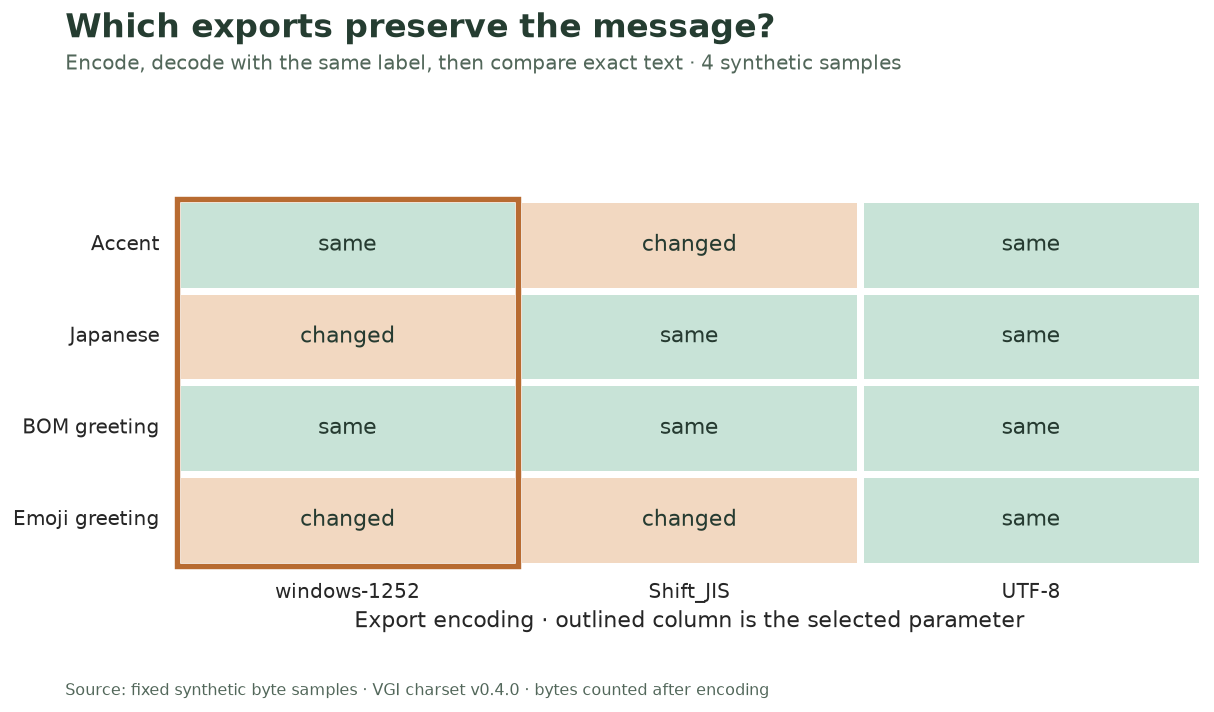

In [13]:
matrix = globals()["matrix"]
encoding_order = ["windows-1252", "Shift_JIS", "UTF-8"]
sample_order = (
    matrix[["id", "sample"]].drop_duplicates().sort_values("id")["sample"].tolist()
)
grid = matrix.pivot(index="sample", columns="encoding", values="text_preserved").loc[
    sample_order, encoding_order
]
fig, ax = plt.subplots(figsize=(9.7, 5.5))
sns.heatmap(
    grid.astype(int),
    ax=ax,
    annot=np.where(grid, "same", "changed"),
    fmt="",
    cmap=ListedColormap(["#f2d8c1", "#c8e3d7"]),
    vmin=0,
    vmax=1,
    cbar=False,
    linewidths=3,
    linecolor="white",
    annot_kws={"size": 12, "color": "#263b31"},
)
ax.add_patch(
    Rectangle(
        (encoding_order.index(EXPORT_ENCODING), 0),
        1,
        len(grid),
        fill=False,
        edgecolor="#b86b31",
        linewidth=3,
        clip_on=False,
    )
)
ax.set(xlabel="Export encoding · outlined column is the selected parameter", ylabel="")
ax.tick_params(axis="both", rotation=0)
finish(
    fig,
    "Which exports preserve the message?",
    "Encode, decode with the same label, then compare exact text · 4 synthetic samples",
    "roundtrips.png",
)

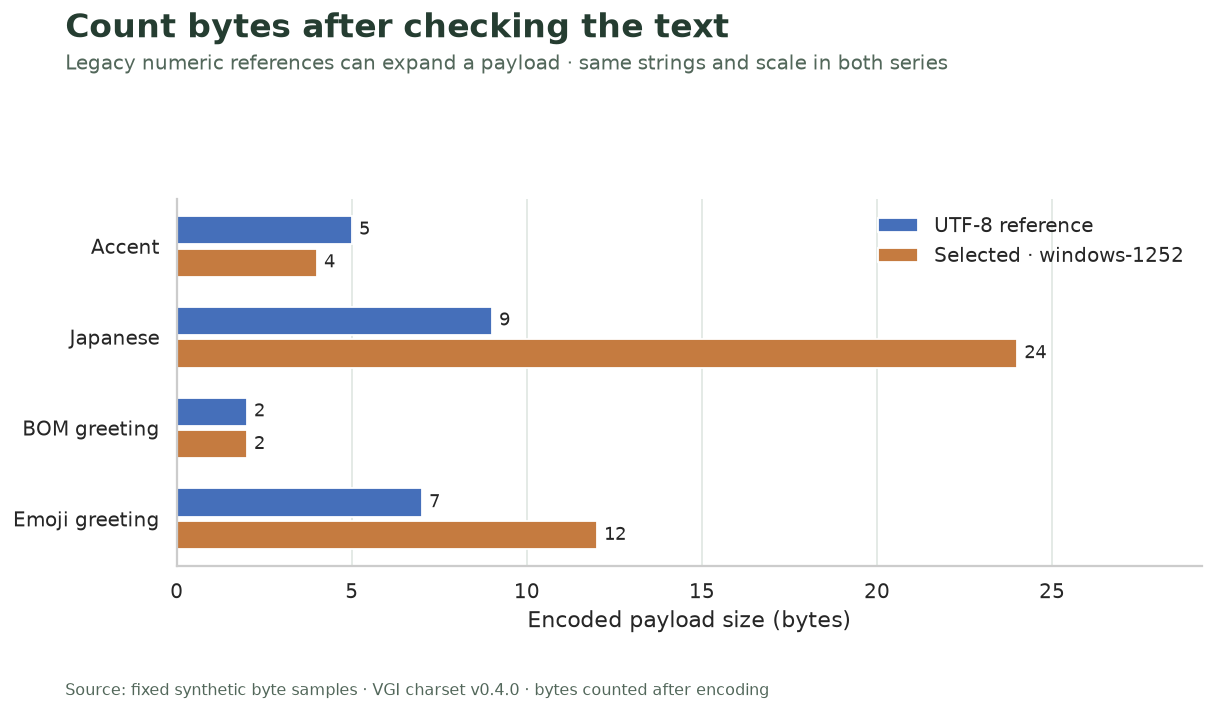

In [14]:
sizes = matrix.pivot(index="sample", columns="encoding", values="byte_count").loc[
    sample_order
]
y = np.arange(len(sizes))
fig, ax = plt.subplots(figsize=(9.7, 5.5))
for offset, encoding, color, label in [
    (-0.18, "UTF-8", COLORS["reference"], "UTF-8 reference"),
    (0.18, EXPORT_ENCODING, COLORS["changed"], f"Selected · {EXPORT_ENCODING}"),
]:
    values = sizes[encoding].to_numpy()
    bars = ax.barh(y + offset, values, height=0.31, color=color, label=label)
    ax.bar_label(bars, padding=4, fontsize=10)
ax.set(
    yticks=y, yticklabels=sample_order, xlabel="Encoded payload size (bytes)", ylabel=""
)
ax.invert_yaxis()
ax.set_xlim(0, max(sizes["UTF-8"].max(), sizes[EXPORT_ENCODING].max()) * 1.22)
ax.grid(axis="y", visible=False)
ax.legend(loc="upper right", frameon=False)
finish(
    fig,
    "Count bytes after checking the text",
    "Legacy numeric references can expand a payload · same strings and scale in both series",
    "encoded-bytes.png",
)

## Check the data relationships

The known source decoders must reproduce their fixture text, and UTF-8 must
round-trip every sample. The full comparison must contain one row per
sample/encoding pair. We deliberately do not demand that every detector guess or
heuristic repair match the supplied intent: their limitations are part of the result.

In [15]:
%%sql checks <<
SELECT 'Declared decode matches fixture' AS check_name,
       count(*) FILTER (WHERE declared_text IS DISTINCT FROM expected_text) AS violations FROM decoded
UNION ALL
SELECT 'UTF-8 preserves all text', count(*) FILTER (WHERE text_preserved IS DISTINCT FROM TRUE)
FROM export_matrix WHERE encoding = 'UTF-8'
UNION ALL
SELECT 'One row per sample and encoding', abs(count(*) - 12) + count(*) - count(DISTINCT (id, encoding))
FROM export_matrix
UNION ALL
SELECT 'Positive byte counts for nonempty samples', count(*) FILTER (WHERE byte_count IS NULL OR byte_count <= 0)
FROM export_matrix;

In [16]:
checks = globals()["checks"]
display(checks)
assert (checks.violations == 0).all(), "A decode or export relationship failed."
assert len(exports) == 4
prose(
    f"All **{len(checks)} relationship checks pass**. Original bytes, encoding labels and fixture expectations remain separate, so guesses cannot become their own ground truth."
)

,check_name,violations
0,Declared decode matches fixture,0
1,UTF-8 preserves all text,0
2,One row per sample and encoding,0
3,Positive byte counts for nonempty samples,0


All **4 relationship checks pass**. Original bytes, encoding labels and fixture expectations remain separate, so guesses cannot become their own ground truth.

## Experiment: switch the destination to UTF-8

Change only **`EXPORT_ENCODING = "UTF-8"`**, then restart and run all.
Predict which altered strings become exact matches and whether every payload
gets smaller. Compare the selected export table, outlined matrix column and
paired byte bars. The source bytes, detector guesses and repair controls should
stay unchanged. Reset to **`windows-1252`** afterward.

The experiment establishes representability for these fixed strings. It does not
prove that an unknown source encoding was correctly identified, nor that a receiving
application will honor the encoding label. Preserve that label when exchanging bytes.

In [17]:
con.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)